# Agentic Memory - LangGraph Setup

Porting the Agentic Memory notebook over from hypothetical to graph-based LLM agent via LangGraph

**Dependencies**

In [15]:
from dotenv import load_dotenv
load_dotenv()
import re
from pathlib import Path
from typing_extensions import TypedDict
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import JsonOutputParser
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
import weaviate

**Connecting to Weviate - Vector Database Instance**

In [16]:
vdb_client = weaviate.connect_to_local(port=8085)
print("Connected to Weviate: ", vdb_client.is_ready())

Connected to Weviate:  True


/mnt/work/agentic-memory/.venv_uv/lib/python3.14/site-packages/weaviate/warnings.py:312: ResourceWarning: Con004: The connection to Weaviate was not closed properly. This can lead to memory leaks.
            Please make sure to close the connection using `client.close()`.
  warnings.warn(


**Instantiating the LLM**

In [17]:
llm = ChatGroq(temperature=0.7, model="qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.3', 'langchain': '1.4.0'}}, client=<groq.resources.chat.completions.Completions object at 0x725792882850>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x72579043f250>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

**Helper Functions from Before**

In [19]:
reflection_prompt_template = """
You are analyzing conversations about research papers to create memories that will help guide future interactions. Your task is to extract key elements that would be most helpful when encountering similar academic discussions in the future.

Review the conversation and create a memory reflection following these rules:

1. For any field where you don't have enough information or the field isn't relevant, use "N/A"
2. Be extremely concise - each string should be one clear, actionable sentence
3. Focus only on information that would be useful for handling similar future conversations
4. Context_tags should be specific enough to match similar situations but general enough to be reusable

Output valid JSON in exactly this format:
{{
    "context_tags": [
        string
    ],
    "conversation_summary": string,
    "what_worked": string,
    "what_to_avoid": string
}}

Here is the prior conversation:

{conversation}
"""

reflection_prompt = ChatPromptTemplate.from_template(reflection_prompt_template)
reflect = reflection_prompt | llm | JsonOutputParser()

def format_conversation(messages):
    conversation = []
    for message in messages:
        conversation.append(f"{message.type.upper()}: {message.content}")
    return "\n".join(conversation)

def episodic_recall(query, vdb_client):
    episodic_memory = vdb_client.collections.get("episodic_memory")
    memory = episodic_memory.query.hybrid(
        query=query,
        alpha=0.5,
        limit=1,
    )
    return memory

def semantic_recall(query, vdb_client):
    coala_collection = vdb_client.collections.get("CoALA_Paper")
    memories = coala_collection.query.hybrid(
        query=query,
        alpha=0.5,
        limit=15,
    )
    combined_text = ""
    for i, memory in enumerate(memories.objects):
        combined_text += f"\nCHUNK {i+1}:\n"
        combined_text += memory.properties['chunk'].strip()
    return combined_text

@tool("search_knowledge_base", description="Search semantic knowledge base.")
def search_knowledge_base(query: str) -> str:
    return semantic_recall(query, vdb_client)

mcp_tools = [search_knowledge_base]
llm_with_tools = llm.bind_tools(mcp_tools)

---
## LangGraph Implementation

**Main State**

In [20]:
class State(TypedDict):
    messages: list
    semantic_memory: str
    procedural_memory: str
    prior_conversations: list
    what_worked: list
    what_to_avoid: list
    end: bool

**First Node - Populate State**

Kicks off the system by populating the state with the initial starting values based on the first message. The back and forth chatting loop relies on having already populated values in the state, so this initial node helps get us there.

In [21]:
def security_middleware(state: State):
    messages = state.get("messages", [])
    if not messages:
        return {"end": False}
    last_msg = messages[-1].content if hasattr(messages[-1], "content") else str(messages[-1])
    patterns = [
        r"ignore previous instructions",
        r"system prompt override",
        r"reveal system prompt",
        r"sudo mode"
    ]
    for pattern in patterns:
        if re.search(pattern, last_msg, re.IGNORECASE):
            warning = SystemMessage(content="Security Alert: Potentially unsafe query detected.")
            return {"messages": messages + [warning], "end": True}
    return {"end": False}

def summarize_history(state: State):
    messages = state["messages"]
    system_msg = messages[0]
    to_summarize = messages[1:-2]
    summary_prompt = f"Summarize the following conversation concisely while preserving key details:\n\n{format_conversation(to_summarize)}"
    summary_res = llm.invoke(summary_prompt)
    summary_msg = SystemMessage(content=f"Summary of prior conversation: {summary_res.content}")
    new_messages = [system_msg, summary_msg] + messages[-2:]
    return {"messages": new_messages}

def should_summarize(state: State):
    if len(state.get("messages", [])) > 10:
        return "summarize"
    return "continue"

In [22]:
def populate_state(state: State):
    initial_messages = []
    first_query = input("User: ")
    first_message = HumanMessage(first_query)

    procedural_path = Path("./langgraph/procedural_memory_lg.txt") if Path("./langgraph/procedural_memory_lg.txt").exists() else Path("./procedural_memory_lg.txt")
    with open(procedural_path, "r") as content:
        procedural_memory = content.read()

    episodic_memory_retrieval = episodic_recall(first_query, vdb_client)
    episodic_memory = episodic_memory_retrieval.objects[0].properties

    prior_conversations = episodic_memory['conversation']
    what_worked = episodic_memory['what_worked']
    what_to_avoid = episodic_memory['what_to_avoid']

    episodic_prompt = f"""You are a helpful AI Assistant. Answer the user's questions to the best of your ability.
You recall similar conversations with the user, here are the details:

Current Conversation Match: {prior_conversations}
Previous Conversations: {"N/A"}
What has worked well: {what_worked}
What to avoid: {what_to_avoid}

Use these memories as context for your response to the user.

Additionally, here are 10 guidelines for interactions with the current user: {procedural_memory}"""

    system_prompt = SystemMessage(episodic_prompt)

    semantic_memory_retrieval = semantic_recall(first_query, vdb_client)

    semantic_prompt = f"""If needed, Use this grounded context to factually answer the next question.
Let me know if you do not have enough information or context to answer a question.

{semantic_memory_retrieval}"""

    semantic_message = HumanMessage(semantic_prompt)

    initial_messages.append(system_prompt)
    initial_messages.append(semantic_message)
    initial_messages.append(first_message)

    return {"messages": initial_messages,
            "semantic_memory": semantic_memory_retrieval,
            "prior_conversations": [episodic_memory['conversation']],
            "what_worked": [episodic_memory['what_worked']],
            "what_to_avoid": [episodic_memory['what_to_avoid']],
            "procedural_memory": procedural_memory,
            "end": False}

**Memory Agent Node**

Main LLM processing step, takes in messages, passes out to Language Model to generate a response back

In [23]:
def memory_agent(state: State):
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    print("\nAI: ", response.content)
    return {"messages": messages + [response]}

**User Response Node**

This node handles the ongoing conversation as well as subsequent user response. In summary it will
1. Load the historical messages, remove the current system prompt and semantic memory recall message
2. Take the user's next message
3. Create the new System Prompt using the retrieved episodic memory data, along with pre-populated procedural memory data
4. Retrieves new context from the Semantic Memory database using the new user message
5. Formats the semantic memory context into a user message itself
6. Attaches the system prompt, historical messages/working memory, and semantic memory + new user message together
7. Returns back to the Memory Agent

In [24]:
def user_response(state: State):
    messages = state['messages']
    messages = messages[1:]
    messages = messages[:-3] + messages[-2:]

    query = input("\nUser: ")

    if query == "exit":
        return {"end": True}
    else:
        episodic_memory_retrieval = episodic_recall(query, vdb_client)
        episodic_memory = episodic_memory_retrieval.objects[0].properties

        current_conversation = episodic_memory['conversation']

        prior_conversations = state['prior_conversations']
        if current_conversation not in prior_conversations:
            prior_conversations.append(current_conversation)

        previous_convos = [conv for conv in prior_conversations[-4:] if conv != current_conversation][-3:]

        state_what_worked = list(set(state['what_worked'] + episodic_memory['what_worked'].split('. ')))
        state_what_to_avoid = list(set(state['what_to_avoid'] + episodic_memory['what_to_avoid'].split('. ')))
        state_procedural_memory = state['procedural_memory']

        episodic_prompt = f"""You are a helpful AI Assistant. Answer the user's questions to the best of your ability.
You recall similar conversations with the user, here are the details:

Current Conversation Match: {current_conversation}
Previous Conversations: {' | '.join(previous_convos)}
What has worked well: {state_what_worked}
What to avoid: {state_what_to_avoid}

Use these memories as context for your response to the user.

Additionally, here are 10 guidelines for interactions with the current user: {state_procedural_memory}"""

        semantic_memory_retrieval = semantic_recall(query, vdb_client)

        semantic_prompt = f"""If needed, Use this grounded context to factually answer the next question.
Let me know if you do not have enough information or context to answer a question.

{semantic_memory_retrieval}"""

        system_message = SystemMessage(episodic_prompt)
        semantic_message = HumanMessage(semantic_prompt)
        user_message = HumanMessage(query)

        final_messages = [system_message]
        final_messages.extend(messages)
        final_messages.append(semantic_message)
        final_messages.append(user_message)

    return {"messages": final_messages,
            "semantic_memory": semantic_memory_retrieval,
            "prior_conversations": prior_conversations,
            "what_worked": state_what_worked,
            "what_to_avoid": state_what_to_avoid,
            "procedural_memory": state_procedural_memory,
            "end": False}

**Update Memory Node**

If the conversation closes, we undergo a memory update step. In this we remove the system prompt and semantic memory context as before and format the conversation into a string.

This is then processed through our existing episodic memory reflection chain to update the episodic database collection in weviate. And then processed through the procedural memory reflection prompt to update the procedural memory file.

In [25]:
def update_memory(state: State):
    messages = state['messages']
    messages = messages[1:]
    messages = messages[:-3] + messages[-2:]

    conversation = format_conversation(messages)

    reflection = reflect.invoke({"conversation": conversation})

    episodic_memory = vdb_client.collections.get("episodic_memory")

    episodic_memory.data.insert({
        "conversation": conversation,
        "context_tags": reflection['context_tags'],
        "conversation_summary": reflection['conversation_summary'],
        "what_worked": reflection['what_worked'],
        "what_to_avoid": reflection['what_to_avoid'],
    })
    print("\n=== Updated Episodic Memory ===")

    procedural_path = Path("./langgraph/procedural_memory_lg.txt") if Path("./langgraph/procedural_memory_lg.txt").exists() else Path("./procedural_memory_lg.txt")
    with open(procedural_path, "r") as content:
        current_takeaways = content.read()

    what_worked = state['what_worked']
    what_to_avoid = state['what_to_avoid']

    procedural_prompt = f"""You are maintaining a continuously updated list of the most important procedural behavior instructions for an AI assistant. Your task is to refine and improve a list of key takeaways based on new conversation feedback while maintaining the most valuable existing insights.

CURRENT TAKEAWAYS:
{current_takeaways}

NEW FEEDBACK:
What Worked Well:
{what_worked}

What To Avoid:
{what_to_avoid}

Please generate an updated list of up to 10 key takeaways that combines:
1. The most valuable insights from the current takeaways
2. New learnings from the recent feedback
3. Any synthesized insights combining multiple learnings

Requirements for each takeaway:
- Must be specific and actionable
- Should address a distinct aspect of behavior
- Include a clear rationale
- Written in imperative form (e.g., "Maintain conversation context by...")

Format each takeaway as:
[#]. [Instruction] - [Brief rationale]

The final list should:
- Be ordered by importance/impact
- Cover a diverse range of interaction aspects
- Focus on concrete behaviors rather than abstract principles
- Preserve particularly valuable existing takeaways
- Incorporate new insights when they provide meaningful improvements

Return up to but no more than 10 takeaways, replacing or combining existing ones as needed to maintain the most effective set of guidelines.
Return just the list, no preamble or explanation."""

    procedural_memory = llm.invoke(procedural_prompt)

    with open(procedural_path, "w") as content:
        content.write(procedural_memory.content)

    print("\n=== Updated Procedural Memory ===")

    return

**Check End Logic Function**

Plugs into conditional edges in our graph to handle when the conversation should stop looping.

In [26]:
def check_end(state):
    if not state["end"]:
        return "continue"
    else:
        return "stop"

**Compiling Main Graph**

In [27]:
graph_builder = StateGraph(State)

graph_builder.add_node("security_middleware", security_middleware)
graph_builder.add_node("populate_state", populate_state)
graph_builder.add_node("summarize_history", summarize_history)
graph_builder.add_node("memory_agent", memory_agent)
graph_builder.add_node("mcp_tools_node", ToolNode(mcp_tools))
graph_builder.add_node("user_response", user_response)
graph_builder.add_node("update_memory", update_memory)

graph_builder.add_edge(START, "security_middleware")
graph_builder.add_conditional_edges(
    "security_middleware",
    lambda state: "blocked" if state.get("end") else "safe",
    {"blocked": END, "safe": "populate_state"}
)
graph_builder.add_conditional_edges(
    "populate_state",
    should_summarize,
    {"summarize": "summarize_history", "continue": "memory_agent"}
)
graph_builder.add_edge("summarize_history", "memory_agent")
graph_builder.add_conditional_edges(
    "memory_agent",
    tools_condition,
    {"tools": "mcp_tools_node", END: "user_response"}
)
graph_builder.add_edge("mcp_tools_node", "memory_agent")
graph_builder.add_conditional_edges(
    "user_response",
    check_end,
    {"continue": "memory_agent", "stop": "update_memory"}
)
graph_builder.add_edge("update_memory", END)

graph = graph_builder.compile()

**Memory Agent Visualization**

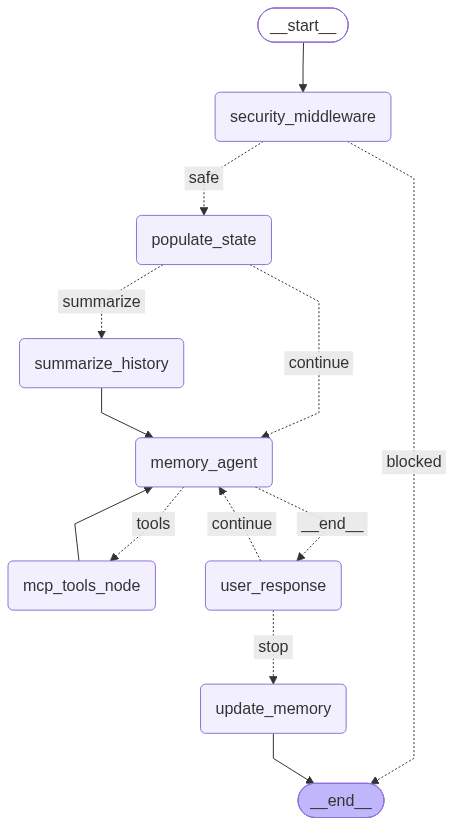

In [28]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

**Trying it Out!**

In [13]:
output = graph.invoke({"messages": [""]})


AI:  Hi Amir! It's nice to see you again. I remember you're an AI engineer who loves the gym and football. How can I help you today?

AI:  Hi Amir! Since you are an AI Engineer, here are 5 strong project ideas for your resume, ranging from LLMs to MLOps, that demonstrate high-level technical skills:

1.  **RAG-Powered Enterprise Search Agent:** Build a system using **LangChain/LlamaIndex** and a vector DB (Pinecone/Chroma) that retrieves internal company docs and answers queries with citations. *Shows: LLM application, RAG, vector search.*
2.  **MLOps Pipeline for Model Monitoring:** Deploy a small model (e.g., sentiment analysis) via **FastAPI/Docker** with **Kubernetes**. Add **Prometheus/Grafana** for logging latency and **drift detection**. *Shows: Deployment, CI/CD, production monitoring.*
3.  **Fine-Tuned Domain-Specific LLM:** Use **LoRA/QLoRA** to fine-tune a small open-source model (e.g., Mistral 7B) on a specific dataset (legal/medical). Include a custom evaluation metric be

**Inspecting the Messages**

In [14]:
for i in range(len(output['messages'])):
    print("="*100, f"\n\nMessage {i+1} - {output['messages'][i].type.upper()}: ", output['messages'][i].content)
    i += 1


Message 1 - SYSTEM:  You are a helpful AI Assistant. Answer the user's questions to the best of your ability.
        You recall similar conversations with the user, here are the details:

        Current Conversation Match: HUMAN: hi
AI: Hi Amir! It’s great to see you again. How are you doing today?
HUMAN: make ai project
AI: Hi Amir! Since you are an AI engineer looking to improve your technical track, building a project is a fantastic way to solidify your skills.

To give you the best recommendation, **what specific area of AI engineering are you currently focusing on?** For example:
*   **LLM Application Building** (RAG, Agents, Fine-tuning)?
*   **MLOps & Deployment** (Scalability, Monitoring, CI/CD)?
*   **Computer Vision or Reinforcement Learning**?
*   **General AI Agents** (using frameworks like LangChain or AutoGen)?

In the meantime, here are **three project ideas** categorized by complexity and focus, tailored for an AI engineer:

### 1. The "LLM Agent" Project (Focus: Age

---
**Check Out an Example LangSmith Trace**

https://smith.langchain.com/public/93f5d5c8-67e8-473b-8e51-648291c2d79a/r